# L1 Logistic Regression: Detecting Phishing URLs
**Saurya Jonchhe | DS 420 Project 1**

## Investigation question
How well does this assigned classifier identify phishing URLs, and what kinds of mistakes does it make? Phishing is the positive class (`1`); benign URLs are `0`. I report accuracy, phishing precision, recall, F1, and ROC AUC, with a majority-class baseline for context.

This notebook runs independently. Select the repository `.venv` Python kernel and run all cells from the repository directory. Dependencies: NumPy, pandas, scikit-learn, matplotlib, and ipykernel.

In [1]:
import warnings
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
)
from dataset_preparation import prepare_datasets

print("scikit-learn version:", sklearn.__version__)
%matplotlib inline

scikit-learn version: 1.6.1


## Experiment setup
The shared preparation module removes exact duplicate rows and creates a reproducible stratified 60/20/20 split. I fit its median imputer and standard scaler on training rows only, then transform dev. Raw URL, domain, and TLD text are excluded from the numeric predictors.

Only dev performance is used for model comparison. I leave test predictors and labels untouched for the final team evaluation.

In [2]:
data = prepare_datasets()
pipeline = data["pipeline"]
X_train = pipeline.fit_transform(data["X_train"])
X_dev = pipeline.transform(data["X_dev"])
y_train = data["y_train"]
y_dev = data["y_dev"]
feature_names = pipeline.get_feature_names_out()

assert "label" not in feature_names
assert not any(name in feature_names for name in ("url", "dom", "tld"))
assert np.isfinite(X_train).all() and np.isfinite(X_dev).all()
assert set(data["X_train"]["url"]).isdisjoint(set(data["X_dev"]["url"]))

split_summary = pd.DataFrame({
    "Split": ["Train", "Dev"],
    "Rows": [len(y_train), len(y_dev)],
    "Phishing rows": [int(y_train.sum()), int(y_dev.sum())],
    "Phishing share": [y_train.mean(), y_dev.mean()],
})
display(split_summary.round(4))
print(f"Prepared numeric features: {len(feature_names)}")
print(f"Training shape: {X_train.shape}; dev shape: {X_dev.shape}")

,Split,Rows,Phishing rows,Phishing share
0,Train,69138,9954,0.144
1,Dev,23046,3318,0.144


Prepared numeric features: 22
Training shape: (69138, 22); dev shape: (23046, 22)


## Why these settings?
L1 regularization can shrink coefficients to zero. The smaller `C=0.1` applies stronger regularization than Sarab's `C=1.0`, and balanced class weights give phishing examples more influence during fitting. `liblinear` supports this L1 configuration. These are the assigned README settings, with no hyperparameter search.

This estimator uses its native solver. It does not implement mini-batch gradient descent; the fixed constructor follows the team's investigation instructions.

In [3]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    penalty="l1",
    C=0.1,
    solver="liblinear",
    class_weight="balanced",
    max_iter=2000,
    random_state=42,
)

## Fit and check the model
I record convergence warnings separately from numerical runtime warnings. Some local NumPy/BLAS installations emit matrix multiplication warnings even with finite outputs. The scoring cell checks each decision score against an independent feature-by-feature sum and stops if the calculations disagree. Warnings are reported rather than silently discarded.

In [4]:
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter("always")
    start = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = perf_counter() - start

convergence_warnings = [str(w.message) for w in captured if issubclass(w.category, ConvergenceWarning)]
print("Fit time (seconds):", round(fit_seconds, 3))
print("Solver iterations:", model.n_iter_)
print("Fit warnings:", sorted(set(str(w.message) for w in captured)) or "None")
assert not convergence_warnings, convergence_warnings

Fit time (seconds): 0.858
Solver iterations: [25]
Fit warnings: None


In [5]:
def measure_split(X, y):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        predicted = model.predict(X)
        decision = model.decision_function(X)
        ranking = model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else decision
    direct = np.einsum("ij,j->i", X, model.coef_[0]) + model.intercept_[0]
    assert np.isfinite(ranking).all() and np.isfinite(decision).all()
    assert np.allclose(decision, direct, rtol=1e-10, atol=1e-10)
    metrics = {
        "Accuracy": accuracy_score(y, predicted),
        "Phishing precision": precision_score(y, predicted, zero_division=0),
        "Phishing recall": recall_score(y, predicted, zero_division=0),
        "Phishing F1": f1_score(y, predicted, zero_division=0),
        "ROC AUC": roc_auc_score(y, ranking),
    }
    return metrics, predicted, ranking, sorted(set(str(w.message) for w in caught))

train_metrics, _, _, train_warnings = measure_split(X_train, y_train)
dev_metrics, dev_predictions, dev_scores, dev_warnings = measure_split(X_dev, y_dev)
metrics = pd.DataFrame({"Train": train_metrics, "Dev": dev_metrics})
display(metrics.round(4))
print("Numerical warnings:", sorted(set(train_warnings + dev_warnings)) or "None")
print("Independent decision-score checks passed for both splits.")
print(f"Always-benign dev baseline: accuracy={1 - y_dev.mean():.4f}, phishing recall=0, F1=0, AUC=0.5")

,Train,Dev
Accuracy,0.9261,0.9249
Phishing precision,0.6782,0.6750
Phishing recall,0.9257,0.9222
Phishing F1,0.7828,0.7795
ROC AUC,0.9761,0.9762


Numerical warnings: ['divide by zero encountered in matmul', 'invalid value encountered in matmul', 'overflow encountered in matmul']
Independent decision-score checks passed for both splits.
Always-benign dev baseline: accuracy=0.8560, phishing recall=0, F1=0, AUC=0.5


## Inspect the errors
The confusion matrix shows the actual counts behind precision and recall. Its lower-left cell contains missed phishing URLs; the upper-right cell contains false alarms. The ROC curve measures ranking across thresholds. Predictions here use the estimator's default threshold, with no threshold tuning.

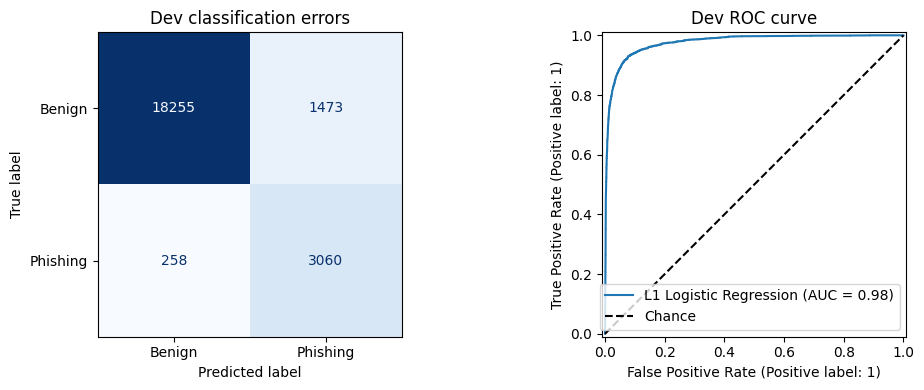

,Dev counts
Correct benign,18255
False alarms,1473
Missed phishing,258
Caught phishing,3060


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_dev, dev_predictions, labels=[0, 1], display_labels=["Benign", "Phishing"],
    values_format="d", cmap="Blues", colorbar=False, ax=axes[0],
)
axes[0].set_title("Dev classification errors")
RocCurveDisplay.from_predictions(y_dev, dev_scores, name="L1 Logistic Regression", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[1].set_title("Dev ROC curve")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_dev, dev_predictions, labels=[0, 1]).ravel()
display(pd.Series({"Correct benign": tn, "False alarms": fp, "Missed phishing": fn, "Caught phishing": tp}, name="Dev counts").to_frame())

## Findings and recommendation

In [7]:
display(Markdown(
    f"On dev, this model achieves **{dev_metrics['Accuracy']:.2%} accuracy**, "
    f"**{dev_metrics['Phishing precision']:.2%} phishing precision**, "
    f"**{dev_metrics['Phishing recall']:.2%} phishing recall**, "
    f"**{dev_metrics['Phishing F1']:.4f} F1**, and **{dev_metrics['ROC AUC']:.4f} ROC AUC**. "
    f"It misses **{fn:,}** phishing URLs and flags **{fp:,}** benign URLs. "
    f"Training F1 is **{train_metrics['Phishing F1']:.4f}**; the train-minus-dev F1 gap is "
    f"**{train_metrics['Phishing F1'] - dev_metrics['Phishing F1']:.4f}**. "
    "A small gap supports consistency on this split, but does not establish performance on future data."
))

On dev, this model achieves **92.49% accuracy**, **67.50% phishing precision**, **92.22% phishing recall**, **0.7795 F1**, and **0.9762 ROC AUC**. It misses **258** phishing URLs and flags **1,473** benign URLs. Training F1 is **0.7828**; the train-minus-dev F1 gap is **0.0033**. A small gap supports consistency on this split, but does not establish performance on future data.

Balanced logistic regression emphasizes catching phishing URLs, but its false alarms also matter. Compare the missed-phishing count with the number of benign URLs flagged before deciding whether this tradeoff is acceptable. Against my fixed-setting linear SVM investigation, this model has higher dev recall (0.9222 versus 0.7260), but lower F1 (0.7795 versus 0.8104). The settings differ in several ways, so this does not isolate the effect of class weighting.

These findings apply to the shared random URL split. Related domains or collection patterns may occur across splits, so a future domain-separated or time-based evaluation would provide stronger evidence of generalization. The team should compare all investigations before assigning grid search. Any tuning should fit preprocessing within each cross-validation fold. The held-out test set has not been scored.